
# Paper 4 Research Framework — Enhanced Thixotropic Giesekus Model

**Paper:** Matthew Armstrong & Andre Pincot (2021), *Integration of thixotropy into Giesekus model for characterization of human blood*, AIP Advances 11, 035029.

## Purpose

This notebook is the first module of a larger cross-paper blood-rheology comparison framework.

It is designed to do four things:

1. **Inspect and compare the raw rheology datasets**
   - file/sheet inventory
   - number of rows and columns
   - data types and missingness
   - numerical summaries
   - distributions
   - rheology-specific visualizations

2. **Reproduce the experimental analysis used in Paper 4**
   - steady-state flow
   - step-up / step-down transient shear
   - SAOS
   - LAOS
   - UD-LAOS
   - harmonic analysis
   - paper-specific cost functions
   - RSS, AIC, BIC
   - physiological/model-parameter correlations

3. **Implement the paper's ethixo-Giesekus model in stages**
   - reported donor parameters
   - steady-state Giesekus backbone
   - thixotropic structure parameter β
   - elastic/plastic strain decomposition
   - rouleaux viscoelastic contribution
   - explicit validation gates for equations that are ambiguous in the printed paper

4. **Export standardized model scores** so later notebooks for Papers 1, 2, 3, and 5 can be compared directly.

---

## Important reproducibility note

The paper gives the governing equations and reported parameter values, but the raw rheometer points are stored in external Mendeley datasets rather than printed numerically in the article.

The paper lists five donor datasets:

| Dataset | DOI |
|---|---|
| DEC17 | `10.17632/d43r5ydpx8.1` |
| FEB18 | `10.17632/jdzpx6hy6r.1` |
| JUN18 | `10.17632/948ffnypjs.1` |
| JUL18 | `10.17632/s8w6s6f68b.1` |
| MAR18b | `10.17632/kpjk7rctmw.1` |

Put the downloaded files under `data/paper4/`.

The notebook deliberately separates:

- **paper-exact formulas** from
- **dimensionally interpreted / exploratory formulas** and
- **common cross-paper metrics**.

That distinction matters because some printed equations in Paper 4 contain apparent typographical or notation ambiguities. Those are flagged rather than silently corrected.


In [1]:
from pathlib import Path
from dataclasses import dataclass, asdict
import math
import re
import json
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.integrate import solve_ivp
from scipy.optimize import least_squares, differential_evolution
from scipy.stats import pearsonr

from IPython.display import display


# ---------------------------------------------------------
# Pandas display settings
# ---------------------------------------------------------
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)


# ---------------------------------------------------------
# LOCAL PROJECT PATHS
# ---------------------------------------------------------

# Folder where this Jupyter notebook is being run
PROJECT_ROOT = Path.cwd()

# Local folder for Paper 4 raw data
DATA_ROOT = PROJECT_ROOT / "data" / "paper4"

# Local folder for Paper 4 generated results
RESULTS_ROOT = PROJECT_ROOT / "results" / "paper4"


# Create the folders if they do not already exist
DATA_ROOT.mkdir(parents=True, exist_ok=True)
RESULTS_ROOT.mkdir(parents=True, exist_ok=True)


print("Project root :", PROJECT_ROOT)
print("Data root    :", DATA_ROOT)
print("Results root :", RESULTS_ROOT)

Project root : c:\Users\vannd\Documents\UniMelb\0_2026S1_Captstone\Capstone_2026S2\Gieskus_Model
Data root    : c:\Users\vannd\Documents\UniMelb\0_2026S1_Captstone\Capstone_2026S2\Gieskus_Model\data\paper4
Results root : c:\Users\vannd\Documents\UniMelb\0_2026S1_Captstone\Capstone_2026S2\Gieskus_Model\results\paper4



## 1. Paper 4 experimental design

Paper 4 uses blood from **five donors** and evaluates the model against several rheological protocols.

The article describes:

- **steady-state shear**
- **four step-down experiments**, starting from \(\dot{\gamma}=5~s^{-1}\)
- **four step-up experiments**, starting from \(\dot{\gamma}=0.25~s^{-1}\)
- **SAOS**
- **LAOS**
- **UD-LAOS**

The article uses a strain-controlled **ARES-G2 rheometer**. Its oscillatory definitions are:

\[
\gamma(t)=\gamma_0\sin(\omega t)
\]

\[
\dot{\gamma}(t)=\gamma_0\omega\cos(\omega t)
\]

for LAOS, and

\[
\gamma(t)=\gamma_0\sin(\omega t)+t\gamma_0\omega
\]

\[
\dot{\gamma}(t)=\gamma_0\omega\cos(\omega t)+\gamma_0\omega
\]

for UD-LAOS.

The paper compares predictions using stress errors, harmonic measures, and information criteria.


In [2]:

DATASET_REGISTRY = pd.DataFrame([
    {"dataset": "DEC17", "doi": "10.17632/d43r5ydpx8.1", "paper_role": "Donor / Dataset 1; SS, SAOS, LAOS, steps"},
    {"dataset": "FEB18", "doi": "10.17632/jdzpx6hy6r.1", "paper_role": "Donor dataset; SS, SAOS, LAOS, steps"},
    {"dataset": "JUN18", "doi": "10.17632/948ffnypjs.1", "paper_role": "Donor dataset; SS, SAOS, steps, LAOS, UD-LAOS"},
    {"dataset": "JUL18", "doi": "10.17632/s8w6s6f68b.1", "paper_role": "Donor dataset; SS, SAOS, LAOS, triangle ramp, UD-LAOS"},
    {"dataset": "MAR18b", "doi": "10.17632/kpjk7rctmw.1", "paper_role": "Donor dataset; SS, SAOS, LAOS, UD-LAOS, triangle ramp"},
])
display(DATASET_REGISTRY)


,dataset,doi,paper_role
0,DEC17,10.17632/d43r5ydpx8.1,"Donor / Dataset 1; SS, SAOS, LAOS, steps"
1,FEB18,10.17632/jdzpx6hy6r.1,"Donor dataset; SS, SAOS, LAOS, steps"
2,JUN18,10.17632/948ffnypjs.1,"Donor dataset; SS, SAOS, steps, LAOS, UD-LAOS"
3,JUL18,10.17632/s8w6s6f68b.1,"Donor dataset; SS, SAOS, LAOS, triangle ramp, ..."
4,MAR18b,10.17632/kpjk7rctmw.1,"Donor dataset; SS, SAOS, LAOS, UD-LAOS, triang..."


## 2. Generic data inventory and exploratory analysis

In [3]:

SUPPORTED_SUFFIXES = {".xlsx", ".xls", ".csv", ".txt", ".dat", ".tsv"}

def discover_data_files(root=DATA_ROOT):
    root = Path(root)
    if not root.exists():
        return pd.DataFrame(columns=["path", "suffix", "size_MB"])
    rows = []
    for p in sorted(root.rglob("*")):
        if p.is_file() and p.suffix.lower() in SUPPORTED_SUFFIXES:
            rows.append({
                "path": str(p),
                "suffix": p.suffix.lower(),
                "size_MB": p.stat().st_size / 1024**2,
            })
    return pd.DataFrame(rows)

files = discover_data_files()
if files.empty:
    print(
        "No raw rheology files found yet. Download the Mendeley datasets and put them under:",
        DATA_ROOT.resolve()
    )
else:
    display(files)


,path,suffix,size_MB
0,c:\Users\vannd\Documents\UniMelb\0_2026S1_Capt...,.xlsx,3.209073
1,c:\Users\vannd\Documents\UniMelb\0_2026S1_Capt...,.xlsx,1.637993
2,c:\Users\vannd\Documents\UniMelb\0_2026S1_Capt...,.xlsx,1.637993
3,c:\Users\vannd\Documents\UniMelb\0_2026S1_Capt...,.xlsx,3.209073


In [6]:
%pip install openpyxl

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [7]:
def read_file_tables(path):
    """
    Read one local Paper 4 data file into a dictionary of raw DataFrames.

    Excel workbooks are loaded sheet-by-sheet with header=None so that
    ARES-G2 metadata and unusual header placement are preserved.
    """

    path = Path(path)

    if not path.exists():
        raise FileNotFoundError(f"File not found: {path}")

    suffix = path.suffix.lower()

    # Excel workbook
    if suffix in {".xlsx", ".xls"}:
        book = pd.ExcelFile(path)

        return {
            f"{path.name}::{sheet}": pd.read_excel(
                path,
                sheet_name=sheet,
                header=None
            )
            for sheet in book.sheet_names
        }

    # CSV
    if suffix == ".csv":
        return {
            path.name: pd.read_csv(
                path,
                header=None
            )
        }

    # TSV
    if suffix == ".tsv":
        return {
            path.name: pd.read_csv(
                path,
                sep="\t",
                header=None
            )
        }

    # TXT / DAT
    if suffix in {".txt", ".dat"}:
        return {
            path.name: pd.read_csv(
                path,
                sep=None,
                engine="python",
                header=None
            )
        }

    raise ValueError(f"Unsupported file type: {suffix}")


def load_all_tables(root=DATA_ROOT):
    """
    Find and load all Paper 4 data files from the local DATA_ROOT folder.
    """

    root = Path(root)

    all_tables = {}

    inventory = discover_data_files(root)

    if inventory.empty:
        return all_tables

    for path in inventory["path"]:

        try:
            tables = read_file_tables(path)
            all_tables.update(tables)

        except Exception as exc:
            print(f"Could not read {path}")
            print(f"Reason: {exc}")
            print()

    return all_tables


def raw_sheet_profile(name, df):
    """
    Produce a basic description of each loaded file/sheet.
    """

    nonempty = df.notna().sum().sum()

    total = max(
        df.shape[0] * df.shape[1],
        1
    )

    numeric = (
        df.apply(pd.to_numeric, errors="coerce")
        .notna()
        .sum()
        .sum()
    )

    return {
        "table": name,
        "rows": df.shape[0],
        "cols": df.shape[1],
        "nonempty_cells": int(nonempty),
        "nonempty_fraction": nonempty / total,
        "numeric_fraction_of_all_cells": numeric / total,
    }


# ---------------------------------------------------------
# LOAD ALL LOCAL PAPER 4 DATA
# ---------------------------------------------------------

print("Loading Paper 4 data from:")
print(DATA_ROOT)
print()


RAW_TABLES = load_all_tables(DATA_ROOT)


# ---------------------------------------------------------
# CREATE DATA INVENTORY
# ---------------------------------------------------------

if RAW_TABLES:

    raw_inventory = pd.DataFrame(
        [
            raw_sheet_profile(name, df)
            for name, df in RAW_TABLES.items()
        ]
    ).sort_values("table").reset_index(drop=True)

    print(f"Successfully loaded {len(RAW_TABLES)} tables/sheets.")
    print()

    display(raw_inventory)

else:

    raw_inventory = pd.DataFrame()

    print("No Paper 4 data files were found.")
    print()
    print("Place the downloaded data files in:")
    print(DATA_ROOT)

Loading Paper 4 data from:
c:\Users\vannd\Documents\UniMelb\0_2026S1_Captstone\Capstone_2026S2\Gieskus_Model\data\paper4

Successfully loaded 18 tables/sheets.



,table,rows,cols,nonempty_cells,nonempty_fraction,numeric_fraction_of_all_cells
0,JUN18.xlsx::Cessation,50,34,1235,0.726471,0.691176
1,JUN18.xlsx::Helton,542,107,28951,0.499207,0.495793
2,JUN18.xlsx::LAOS,2008,73,110065,0.750866,0.750027
3,JUN18.xlsx::SRFS,272,23,4884,0.780691,0.773977
4,JUN18.xlsx::Steady State & SAOS,29,19,354,0.642468,0.591652
5,JUN18.xlsx::Step Up Step Down,4189,69,20250,0.070059,0.069623
6,JUN18.xlsx::UDLAOS,1507,17,14006,0.546704,0.545533
7,JUN18.xlsx::reversal,303,23,3279,0.470512,0.464916
8,UDEL Blood DEC17 SS SAOS LAOS STEPS RAMPS HELT...,331,63,6527,0.313001,0.309308
9,UDEL Blood DEC17 SS SAOS LAOS STEPS RAMPS HELT...,331,63,6527,0.313001,0.309308


In [8]:

EXPERIMENT_KEYWORDS = {
    "UD-LAOS": ["udlaos", "ud-laos", "unidirectional"],
    "LAOS": ["laos"],
    "SAOS": ["saos", "amplitude sweep", "frequency sweep", "amp sweep", "freq sweep"],
    "STEP": ["step", "step up", "step down"],
    "STEADY_STATE": ["steady", "steady state", " ss "],
    "TRIANGLE_RAMP": ["triangle", "ramp"],
    "HELTON_OR_OTHER": ["helton"],
}

def infer_experiment_type(text):
    t = f" {str(text).lower()} "
    # UD-LAOS must be checked before LAOS.
    for exp, kws in EXPERIMENT_KEYWORDS.items():
        if any(k in t for k in kws):
            return exp
    return "UNKNOWN"


def classify_loaded_tables(raw_tables=RAW_TABLES):
    return pd.DataFrame([
        {
            "table": name,
            "experiment_guess": infer_experiment_type(name),
            "rows": df.shape[0],
            "cols": df.shape[1],
        }
        for name, df in raw_tables.items()
    ])

if RAW_TABLES:
    display(classify_loaded_tables())


,table,experiment_guess,rows,cols
0,JUN18.xlsx::Steady State & SAOS,SAOS,29,19
1,JUN18.xlsx::Helton,HELTON_OR_OTHER,542,107
2,JUN18.xlsx::Step Up Step Down,STEP,4189,69
3,JUN18.xlsx::LAOS,LAOS,2008,73
4,JUN18.xlsx::reversal,UNKNOWN,303,23
5,JUN18.xlsx::Cessation,UNKNOWN,50,34
6,JUN18.xlsx::SRFS,UNKNOWN,272,23
7,JUN18.xlsx::UDLAOS,UD-LAOS,1507,17
8,UDEL Blood DEC17 SS SAOS LAOS STEPS RAMPS HELT...,LAOS,29,46
9,UDEL Blood DEC17 SS SAOS LAOS STEPS RAMPS HELT...,LAOS,2008,67


In [9]:

def search_cells(raw_tables, keywords, max_hits=100):
    """Search raw workbook cells for terms such as 'stress', 'time', 'shear rate'."""
    if isinstance(keywords, str):
        keywords = [keywords]
    keys = [k.lower() for k in keywords]

    hits = []
    for table_name, df in raw_tables.items():
        for r in range(df.shape[0]):
            for c in range(df.shape[1]):
                value = df.iat[r, c]
                if pd.isna(value):
                    continue
                txt = str(value).lower()
                if any(k in txt for k in keys):
                    hits.append({
                        "table": table_name,
                        "row": r,
                        "col": c,
                        "value": value,
                    })
                    if len(hits) >= max_hits:
                        return pd.DataFrame(hits)
    return pd.DataFrame(hits)

if RAW_TABLES:
    display(search_cells(RAW_TABLES, ["stress", "shear rate", "time", "strain"], max_hits=50))


,table,row,col,value
0,JUN18.xlsx::Steady State & SAOS,1,0,Shear Rate (1/s)
1,JUN18.xlsx::Steady State & SAOS,1,1,Stress (Pa)
2,JUN18.xlsx::Steady State & SAOS,1,4,Shear Rate (1/s)
3,JUN18.xlsx::Steady State & SAOS,1,5,Stress (Pa)
4,JUN18.xlsx::Steady State & SAOS,1,9,Oscillation strain
5,JUN18.xlsx::Steady State & SAOS,1,15,Oscillation strain
6,JUN18.xlsx::Helton,1,0,Step time
7,JUN18.xlsx::Helton,1,1,Strain
8,JUN18.xlsx::Helton,1,3,Stress
9,JUN18.xlsx::Helton,1,6,Step time



### 2.1 Convert a raw sheet into a tidy table

ARES-G2 exports may have metadata above the actual column header. The helper below lets you choose a sheet and header row **without modifying the original data**.

Example:

```python
tidy = tidy_from_raw(
    RAW_TABLES["UDEL Blood DEC17 SS SAOS LAOS STEPS RAMPS HELTON.xlsx::SS"],
    header_row=12
)
```

After inspecting the workbook, create a mapping for each experiment.


In [10]:

def tidy_from_raw(raw_df, header_row, drop_empty=True):
    header = raw_df.iloc[header_row].astype(str).str.strip()
    df = raw_df.iloc[header_row + 1:].copy()
    df.columns = header
    if drop_empty:
        df = df.dropna(how="all").dropna(axis=1, how="all")
    df = df.reset_index(drop=True)

    # Convert columns to numeric only when most non-missing values are numeric.
    for col in df.columns:
        converted = pd.to_numeric(df[col], errors="coerce")
        nonmissing = df[col].notna().sum()
        numeric_nonmissing = converted.notna().sum()
        if nonmissing > 0 and numeric_nonmissing / nonmissing >= 0.8:
            df[col] = converted
    return df


def profile_tidy_dataframe(df):
    summary = {
        "rows": len(df),
        "cols": df.shape[1],
        "duplicate_rows": int(df.duplicated().sum()),
        "numeric_cols": int(df.select_dtypes(include=np.number).shape[1]),
        "non_numeric_cols": int(df.select_dtypes(exclude=np.number).shape[1]),
    }
    missing = pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "missing_n": df.isna().sum(),
        "missing_pct": 100 * df.isna().mean(),
        "unique_n": df.nunique(dropna=True),
    }).sort_values("missing_pct", ascending=False)
    return summary, missing


def plot_numeric_distributions(df, max_cols=12, bins=30):
    num = df.select_dtypes(include=np.number)
    cols = list(num.columns[:max_cols])
    if not cols:
        print("No numeric columns to plot.")
        return
    for col in cols:
        values = num[col].dropna().to_numpy()
        if len(values) == 0:
            continue
        plt.figure(figsize=(7, 4))
        plt.hist(values, bins=bins)
        plt.xlabel(str(col))
        plt.ylabel("Count")
        plt.title(f"Distribution: {col}")
        plt.tight_layout()
        plt.show()


def numeric_summary(df):
    num = df.select_dtypes(include=np.number)
    if num.empty:
        return pd.DataFrame()
    q = num.quantile([0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).T
    q.columns = [f"q{int(x*100):02d}" for x in q.columns]
    base = num.agg(["count", "mean", "std", "min", "max"]).T
    return base.join(q)


## 3. Rheology-specific visualization helpers

In [11]:

def plot_steady_state(df, shear_rate_col, stress_col, viscosity_col=None, title="Steady-state flow curve"):
    d = df[[shear_rate_col, stress_col] + ([viscosity_col] if viscosity_col else [])].dropna()
    d = d[(d[shear_rate_col] > 0)]

    plt.figure(figsize=(7, 5))
    plt.loglog(d[shear_rate_col], np.abs(d[stress_col]), "o-")
    plt.xlabel(r"Shear rate $\dot{\gamma}$ (s$^{-1}$)")
    plt.ylabel("Stress magnitude (Pa)")
    plt.title(title)
    plt.tight_layout()
    plt.show()

    if viscosity_col:
        plt.figure(figsize=(7, 5))
        plt.loglog(d[shear_rate_col], np.abs(d[viscosity_col]), "o-")
        plt.xlabel(r"Shear rate $\dot{\gamma}$ (s$^{-1}$)")
        plt.ylabel("Viscosity (Pa s)")
        plt.title(title + " — viscosity")
        plt.tight_layout()
        plt.show()


def plot_transient(df, time_col, stress_col, shear_rate_col=None, title="Transient rheology"):
    d = df.dropna(subset=[time_col, stress_col]).copy()

    plt.figure(figsize=(8, 4))
    plt.plot(d[time_col], d[stress_col])
    plt.xlabel("Time (s)")
    plt.ylabel("Stress (Pa)")
    plt.title(title + " — stress")
    plt.tight_layout()
    plt.show()

    if shear_rate_col:
        plt.figure(figsize=(8, 4))
        plt.plot(d[time_col], d[shear_rate_col])
        plt.xlabel("Time (s)")
        plt.ylabel(r"Shear rate (s$^{-1}$)")
        plt.title(title + " — imposed shear rate")
        plt.tight_layout()
        plt.show()


def plot_lissajous(df, strain_col, shear_rate_col, stress_col, title="Oscillatory shear"):
    d = df[[strain_col, shear_rate_col, stress_col]].dropna()

    plt.figure(figsize=(6, 5))
    plt.plot(d[strain_col], d[stress_col])
    plt.xlabel("Strain")
    plt.ylabel("Stress (Pa)")
    plt.title(title + " — elastic projection")
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(6, 5))
    plt.plot(d[shear_rate_col], d[stress_col])
    plt.xlabel(r"Shear rate (s$^{-1}$)")
    plt.ylabel("Stress (Pa)")
    plt.title(title + " — viscous projection")
    plt.tight_layout()
    plt.show()


def estimate_sampling(df, time_col):
    t = pd.to_numeric(df[time_col], errors="coerce").dropna().to_numpy()
    if len(t) < 3:
        return {"n": len(t), "median_dt_s": np.nan, "estimated_fs_Hz": np.nan}
    dt = np.diff(t)
    dt = dt[np.isfinite(dt) & (dt > 0)]
    if len(dt) == 0:
        return {"n": len(t), "median_dt_s": np.nan, "estimated_fs_Hz": np.nan}
    median_dt = float(np.median(dt))
    return {
        "n": len(t),
        "median_dt_s": median_dt,
        "estimated_fs_Hz": 1.0 / median_dt,
        "dt_cv": float(np.std(dt) / np.mean(dt)) if np.mean(dt) else np.nan,
    }


## 4. Paper-reported donor physiology and ethixo-Giesekus parameters

In [12]:

physiology = pd.DataFrame({
    "Donor": [1, 2, 3, 4, 5],
    "HCT_percent": [42.9, 46.2, 38.3, 45.2, 43.1],
    "Fibrinogen_mg_dl": [0.242, 0.316, 0.333, 0.214, 0.249],
    "Total_cholesterol_mg_ml": [138, 132, 145, 187, 244],
    "Triglycerides_mg_ml": [108, 111, 144, 57, 94],
    "HDL_mg_ml": [35, 41, 39, 65, 70],
    "LDL_mg_ml": [83, 72, 82, 108, 154],
})
display(physiology)


,Donor,HCT_percent,Fibrinogen_mg_dl,Total_cholesterol_mg_ml,Triglycerides_mg_ml,HDL_mg_ml,LDL_mg_ml
0,1,42.9,0.242,138,108,35,83
1,2,46.2,0.316,132,111,41,72
2,3,38.3,0.333,145,144,39,82
3,4,45.2,0.214,187,57,65,108
4,5,43.1,0.249,244,94,70,154


In [14]:

# Table IV of Paper 4.
reported_params = pd.DataFrame({
    "Donor": [1, 2, 3, 4, 5],
    "eta0": [0.0051, 0.0080, 0.0047, 0.0048, 0.0075],
    "eta_s": [0.0031, 0.0036, 0.0030, 0.0035, 0.0034],
    "eta_p": [0.0020, 0.0044, 0.0018, 0.0013, 0.0041],
    "lambda1": [0.0270, 0.2133, 0.3982, 0.0187, 0.2956],
    "lambda2": [0.0164, 0.0955, 0.2491, 0.0135, 0.1339],
    "alpha": [0.3068, 0.0062, 0.0005, 0.1922, 0.0057],
    "tr1": [0.5081, 0.3063, 0.4531, 0.3016, 0.5618],
    "tr2": [0.1126, 0.0240, 0.2038, 0.1351, 0.0035],
    "muR": [0.0181, 0.0275, 0.0217, 0.0179, 0.0487],
    "tau_y0": [0.0027, 0.0022, 0.0021, 0.0030, 0.0037],
    "m": [1.2812, 1.9355, 1.8814, 1.4506, 1.6370],
    "tau_beta": [0.61, 1.13, 1.67, 0.65, 0.5921],
    "G_R": [0.25, 0.77, 0.43, 0.28, 0.5362],
    "gamma0_R": [1, 1, 1, 1, 1],
    "Fcost_SS": [0.0037, 0.0187, 0.0052, 0.0109, 0.0221],
    "Fcost_trans": [0.00056, 0.00072, 0.00051, 0.00048, 0.00122],
})
display(reported_params)


,Donor,eta0,eta_s,eta_p,lambda1,lambda2,alpha,tr1,tr2,muR,tau_y0,m,tau_beta,G_R,gamma0_R,Fcost_SS,Fcost_trans
0,1,0.0051,0.0031,0.0020,0.0270,0.0164,0.3068,0.5081,0.1126,0.0181,0.0027,1.2812,0.6100,0.2500,1,0.0037,0.00056
1,2,0.0080,0.0036,0.0044,0.2133,0.0955,0.0062,0.3063,0.0240,0.0275,0.0022,1.9355,1.1300,0.7700,1,0.0187,0.00072
2,3,0.0047,0.0030,0.0018,0.3982,0.2491,0.0005,0.4531,0.2038,0.0217,0.0021,1.8814,1.6700,0.4300,1,0.0052,0.00051
3,4,0.0048,0.0035,0.0013,0.0187,0.0135,0.1922,0.3016,0.1351,0.0179,0.0030,1.4506,0.6500,0.2800,1,0.0109,0.00048
4,5,0.0075,0.0034,0.0041,0.2956,0.1339,0.0057,0.5618,0.0035,0.0487,0.0037,1.6370,0.5921,0.5362,1,0.0221,0.00122


In [15]:

@dataclass
class EthixoGiesekusParams:
    eta0: float
    eta_s: float
    eta_p: float
    lambda1: float
    lambda2: float
    alpha: float
    tr1: float
    tr2: float
    muR: float
    tau_y0: float
    m: float
    tau_beta: float
    G_R: float
    gamma0_R: float = 1.0

def params_for_donor(donor=1):
    row = reported_params.loc[reported_params["Donor"] == donor].iloc[0]
    return EthixoGiesekusParams(
        eta0=row.eta0,
        eta_s=row.eta_s,
        eta_p=row.eta_p,
        lambda1=row.lambda1,
        lambda2=row.lambda2,
        alpha=row.alpha,
        tr1=row.tr1,
        tr2=row.tr2,
        muR=row.muR,
        tau_y0=row.tau_y0,
        m=row.m,
        tau_beta=row.tau_beta,
        G_R=row.G_R,
        gamma0_R=row.gamma0_R,
    )

P1 = params_for_donor(1)
P1


EthixoGiesekusParams(eta0=np.float64(0.0051), eta_s=np.float64(0.0031), eta_p=np.float64(0.002), lambda1=np.float64(0.027), lambda2=np.float64(0.0164), alpha=np.float64(0.3068), tr1=np.float64(0.5081), tr2=np.float64(0.1126), muR=np.float64(0.0181), tau_y0=np.float64(0.0027), m=np.float64(1.2812), tau_beta=np.float64(0.61), G_R=np.float64(0.25), gamma0_R=np.float64(1.0))


## 5. Paper 4 model: steady-state components

### 5.1 Giesekus viscoelastic backbone

Paper 4 Table I gives the steady-state Giesekus contribution as

\[
\tau_{ve,plasma}=\eta(\dot{\gamma})\dot{\gamma}.
\]

The helper below implements the Table I steady-state expression.

### 5.2 Structure parameter

Paper Eq. (13):

\[
\beta_{ss} =
\frac{tr_2|\dot{\gamma}|^{1/2}+1}
{tr_1|\dot{\gamma}|+tr_2|\dot{\gamma}|^{1/2}+1}.
\]

### 5.3 Important Eq. (14) validation issue

The printed Eq. (14) is

\[
\tau_{ss}=\tau_{ve,ss}+\mu_r\beta_{ss}^{m}+\tau_{y,0}\beta_{ss}.
\]

However, \(\mu_r\) is described with viscosity units of Pa·s, so the second term as printed does not have stress units unless another factor is implicit.

Therefore this notebook provides **two variants**:

- `steady_total_stress_as_printed()` — reproduces the article literally.
- `steady_total_stress_dimensional()` — multiplies the structural viscosity term by shear rate, as a dimensional interpretation.

Do not declare one “correct” until it is checked against the raw data and/or author source code.


In [16]:

def beta_ss(gdot, p):
    g = np.abs(np.asarray(gdot, dtype=float))
    return (p.tr2 * np.sqrt(g) + 1.0) / (
        p.tr1 * g + p.tr2 * np.sqrt(g) + 1.0
    )


def giesekus_eta_ss(gdot, p, eps=1e-14):
    """Steady-state viscosity expression transcribed from Paper 4, Table I."""
    g = np.abs(np.asarray(gdot, dtype=float))
    lam1 = p.lambda1
    lam2 = p.lambda2
    alpha = p.alpha

    A = alpha * (1.0 - alpha) * (lam1 * g) ** 2
    chi2 = np.ones_like(g, dtype=float)

    mask = np.abs(A) > eps
    chi2[mask] = (
        np.sqrt(1.0 + 16.0 * A[mask]) - 1.0
    ) / (8.0 * A[mask])
    chi2 = np.maximum(chi2, 0.0)
    chi = np.sqrt(chi2)

    f = (1.0 - chi) / (1.0 + (1.0 - 2.0 * alpha) * chi)
    ratio = (
        lam2 / lam1
        + (1.0 - lam2 / lam1)
        * ((1.0 - f) / (1.0 + (1.0 - 2.0 * alpha) * f))
    )
    return p.eta0 * ratio


def tau_ve_ss(gdot, p):
    gdot = np.asarray(gdot, dtype=float)
    return giesekus_eta_ss(gdot, p) * gdot


def steady_total_stress_as_printed(gdot, p):
    gdot = np.asarray(gdot, dtype=float)
    beta = beta_ss(gdot, p)
    return tau_ve_ss(gdot, p) + p.muR * beta**p.m + p.tau_y0 * beta


def steady_total_stress_dimensional(gdot, p):
    gdot = np.asarray(gdot, dtype=float)
    beta = beta_ss(gdot, p)
    return (
        tau_ve_ss(gdot, p)
        + p.muR * beta**p.m * gdot
        + p.tau_y0 * beta
    )


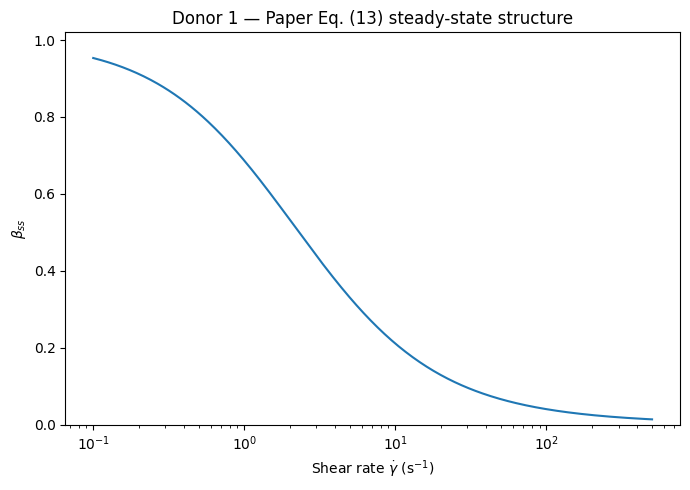

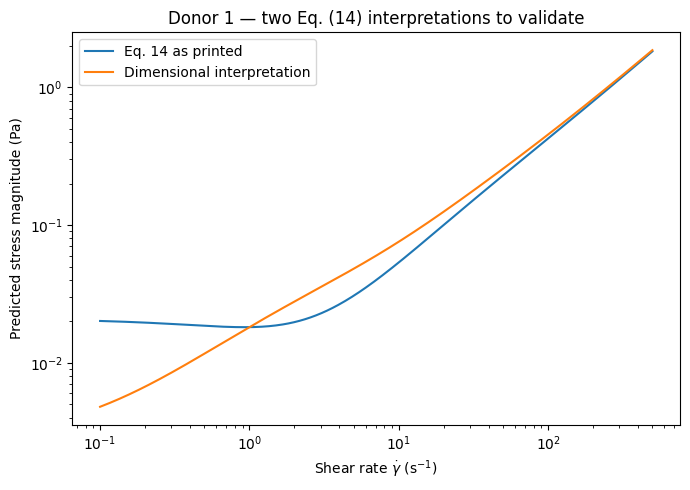

In [13]:

g_grid = np.logspace(-1, np.log10(500), 400)

plt.figure(figsize=(7, 5))
plt.semilogx(g_grid, beta_ss(g_grid, P1))
plt.xlabel(r"Shear rate $\dot{\gamma}$ (s$^{-1}$)")
plt.ylabel(r"$\beta_{ss}$")
plt.ylim(0, 1.02)
plt.title("Donor 1 — Paper Eq. (13) steady-state structure")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 5))
plt.loglog(g_grid, np.abs(steady_total_stress_as_printed(g_grid, P1)), label="Eq. 14 as printed")
plt.loglog(g_grid, np.abs(steady_total_stress_dimensional(g_grid, P1)), label="Dimensional interpretation")
plt.xlabel(r"Shear rate $\dot{\gamma}$ (s$^{-1}$)")
plt.ylabel("Predicted stress magnitude (Pa)")
plt.title("Donor 1 — two Eq. (14) interpretations to validate")
plt.legend()
plt.tight_layout()
plt.show()



## 6. Transient thixotropic structure and rouleaux module

Paper Eqs. (7)–(12) describe:

- structure evolution \(\beta(t)\)
- plastic shear rate \(\dot{\gamma}_p\)
- maximum elastic strain \(\gamma_{max}\)
- elastic strain evolution \(\dot{\gamma}_e\)
- elastic rouleaux stress
- viscoelastic rouleaux stress

This section implements those equations directly from the printed paper.

It produces the **rouleaux contribution** and the predicted structure parameter. The full transient total stress additionally requires the Giesekus tensor backbone from Table I. Because some terms in the printed transient Table I are notation/typography ambiguous, that part is kept behind a validation gate rather than silently guessed.


In [17]:

def plastic_shear_rate(imposed_gdot, beta, gamma_e, p, eps=1e-12):
    beta_safe = float(np.clip(beta, eps, 1.0))
    gamma_max = p.gamma0_R * beta_safe

    if imposed_gdot >= 0:
        denom = 2.0 - gamma_e / gamma_max
    else:
        denom = 2.0 + gamma_e / gamma_max

    if abs(denom) < eps:
        denom = eps if denom >= 0 else -eps
    return imposed_gdot / denom


def rouleaux_rhs(t, y, imposed_gdot, p):
    """Paper Eqs. (7)-(12).

    State:
        y[0] = beta
        y[1] = gamma_e
        y[2] = tau_r_ve
    """
    beta, gamma_e, tau_r_ve = y
    beta_safe = float(np.clip(beta, 1e-10, 1.0))
    gamma_max = p.gamma0_R * beta_safe

    gdot_p = plastic_shear_rate(imposed_gdot, beta_safe, gamma_e, p)

    beta_dot = (
        -p.tr1 * beta_safe * abs(gdot_p)
        + p.tr2 * (1.0 - beta_safe) * np.sqrt(abs(gdot_p))
        + (1.0 - beta_safe)
    ) / p.tau_beta

    gamma_max_dot = p.gamma0_R * beta_dot

    gamma_e_dot_base = gdot_p - (gamma_e / gamma_max) * abs(gdot_p)
    if gamma_max_dot >= 0:
        gamma_e_dot = gamma_e_dot_base
    else:
        gamma_e_dot = gamma_e_dot_base + (gamma_e / gamma_max) * gamma_max_dot

    structural_visc_denom = p.muR * beta_safe**p.m
    structural_visc_denom = max(structural_visc_denom, 1e-14)

    tau_r_ve_dot = p.G_R * beta_safe**p.m * (
        gdot_p - tau_r_ve / structural_visc_denom
    )
    if beta_dot < 0:
        tau_r_ve_dot += p.m * (tau_r_ve / beta_safe) * beta_dot

    return [beta_dot, gamma_e_dot, tau_r_ve_dot]


def tau_r_elastic_as_printed(beta, p):
    # Paper Eq. (11), transcribed literally.
    return (p.tau_y0 / p.gamma0_R) * beta


def simulate_rouleaux_step(initial_gdot, final_gdot, p=P1, t_end=30.0, n=600):
    beta0 = float(beta_ss(initial_gdot, p))
    gamma_e0 = p.gamma0_R * beta0

    # At steady shear, use the steady-state structural viscosity contribution
    # as an initial condition for tau_r_ve.
    tau_r_ve0 = p.muR * beta0**p.m * initial_gdot

    t_eval = np.unique(
        np.concatenate(([0.0], np.logspace(-4, np.log10(t_end), n)))
    )

    sol = solve_ivp(
        lambda t, y: rouleaux_rhs(t, y, final_gdot, p),
        (0.0, t_end),
        [beta0, gamma_e0, tau_r_ve0],
        t_eval=t_eval,
        method="LSODA",
        rtol=1e-8,
        atol=1e-10,
    )

    out = pd.DataFrame({
        "time_s": sol.t,
        "beta": np.clip(sol.y[0], 0, 1),
        "gamma_e": sol.y[1],
        "tau_r_ve_Pa": sol.y[2],
    })
    out["tau_r_e_Pa_as_printed"] = tau_r_elastic_as_printed(out["beta"], p)
    out["tau_rouleaux_Pa"] = out["tau_r_ve_Pa"] + out["tau_r_e_Pa_as_printed"]
    out["initial_gdot_s-1"] = initial_gdot
    out["final_gdot_s-1"] = final_gdot
    return out


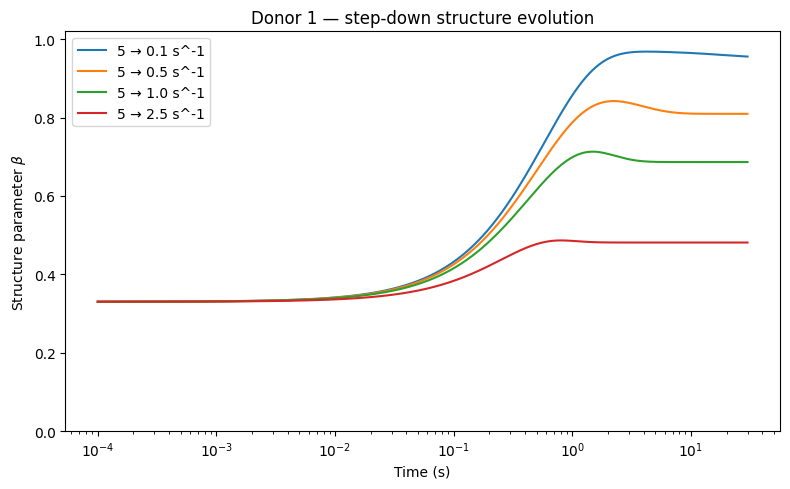

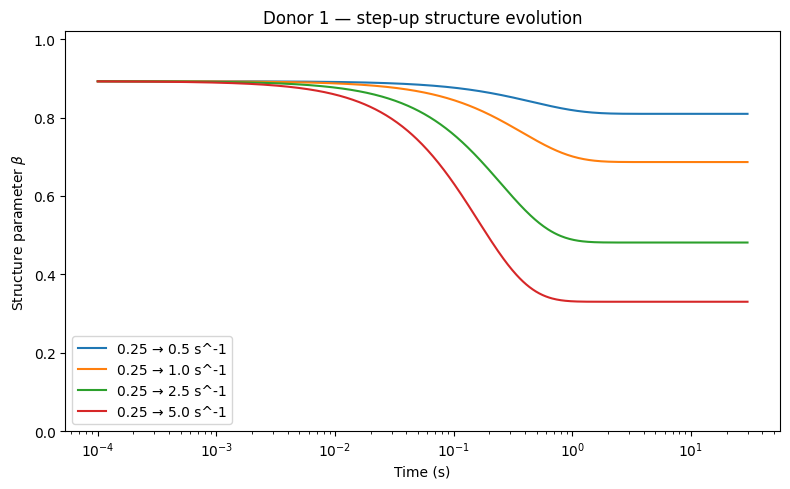

In [15]:

# Reproduce the structure-evolution logic behind Paper Fig. 1(c) and 1(e).
step_down_rates = [0.1, 0.5, 1.0, 2.5]
step_up_rates = [0.5, 1.0, 2.5, 5.0]

step_down_sims = {
    r: simulate_rouleaux_step(5.0, r, P1)
    for r in step_down_rates
}
step_up_sims = {
    r: simulate_rouleaux_step(0.25, r, P1)
    for r in step_up_rates
}

plt.figure(figsize=(8, 5))
for r, d in step_down_sims.items():
    q = d[d["time_s"] > 0]
    plt.semilogx(q["time_s"], q["beta"], label=f"5 → {r} s^-1")
plt.xlabel("Time (s)")
plt.ylabel(r"Structure parameter $\beta$")
plt.ylim(0, 1.02)
plt.title("Donor 1 — step-down structure evolution")
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
for r, d in step_up_sims.items():
    q = d[d["time_s"] > 0]
    plt.semilogx(q["time_s"], q["beta"], label=f"0.25 → {r} s^-1")
plt.xlabel("Time (s)")
plt.ylabel(r"Structure parameter $\beta$")
plt.ylim(0, 1.02)
plt.title("Donor 1 — step-up structure evolution")
plt.legend()
plt.tight_layout()
plt.show()



## 7. Paper-native evaluation metrics

Paper 4 uses several different cost functions.

### Steady state — Eq. (21)

\[
F_{cost,ss}
=
\frac{1}{N}
\sqrt{
\sum_i
\left(
\frac{y_i-f_i}{y_i}
\right)^2
}
\]

### Transient steps — Eq. (22)

The paper averages an unnormalized root-sum error over the step tests.

### LAOS — Eq. (23)

\[
F_{cost,LAOS}
=
\frac{1}{N}
\sqrt{\sum_i(y_i-f_i)^2}
\]

### SAOS — Eq. (24)

The paper compares differences in \(G'\) and \(G''\).

### RSS / AIC / BIC caution

The printed Eq. (25) labels

\[
\sum_i\sqrt{(y_i-f_i)^2}
\]

as “RSS”. Algebraically, this is a sum of absolute residual magnitudes, not conventional residual sum of squares.

For research transparency, the notebook calculates both:

- `paper_rss_like()` — exactly what the printed Eq. (25) shows
- `conventional_rss()` — \(\sum_i(y_i-f_i)^2\)

The paper's AIC/BIC formulas are also preserved separately from conventional alternatives.


In [18]:

def fcost_ss_paper(y, f):
    y = np.asarray(y, dtype=float)
    f = np.asarray(f, dtype=float)
    mask = np.isfinite(y) & np.isfinite(f) & (np.abs(y) > 1e-15)
    y, f = y[mask], f[mask]
    if len(y) == 0:
        return np.nan
    return np.sqrt(np.sum(((y - f) / y) ** 2)) / len(y)


def fcost_single_trace_paper(y, f):
    y = np.asarray(y, dtype=float)
    f = np.asarray(f, dtype=float)
    mask = np.isfinite(y) & np.isfinite(f)
    y, f = y[mask], f[mask]
    if len(y) == 0:
        return np.nan
    return np.sqrt(np.sum((y - f) ** 2)) / len(y)


def fcost_transient_paper(traces):
    """traces = iterable of (y, f) pairs; Paper Eq. (22)."""
    vals = [fcost_single_trace_paper(y, f) for y, f in traces]
    vals = [v for v in vals if np.isfinite(v)]
    return np.mean(vals) if vals else np.nan


def fcost_saos_paper(Gp_data, Gp_model, Gpp_data, Gpp_model):
    Gp_data = np.asarray(Gp_data, dtype=float)
    Gp_model = np.asarray(Gp_model, dtype=float)
    Gpp_data = np.asarray(Gpp_data, dtype=float)
    Gpp_model = np.asarray(Gpp_model, dtype=float)
    n = len(Gp_data)
    if n == 0:
        return np.nan
    # Eq. (24) as printed reduces to mean absolute deviation over G' and G''.
    return (
        np.sum(np.abs(Gp_data - Gp_model) + np.abs(Gpp_data - Gpp_model))
        / (2 * n)
    )


def paper_rss_like(y, f):
    """Literal Eq. (25) from Paper 4: sum(sqrt((y-f)^2))."""
    r = np.asarray(y, dtype=float) - np.asarray(f, dtype=float)
    r = r[np.isfinite(r)]
    return np.sum(np.abs(r))


def conventional_rss(y, f):
    r = np.asarray(y, dtype=float) - np.asarray(f, dtype=float)
    r = r[np.isfinite(r)]
    return np.sum(r**2)


def paper_aic(rss_like, k):
    return 2 * k + 2 * np.log(rss_like)


def paper_bic(rss_like, k, n):
    return 2 * k * np.log(n) + 2 * np.log(rss_like)


def common_metrics(y, f, k=None):
    y = np.asarray(y, dtype=float)
    f = np.asarray(f, dtype=float)
    mask = np.isfinite(y) & np.isfinite(f)
    y, f = y[mask], f[mask]
    if len(y) == 0:
        return {}

    r = y - f
    rss = float(np.sum(r**2))
    rmse = float(np.sqrt(np.mean(r**2)))
    mae = float(np.mean(np.abs(r)))
    denom = float(np.max(y) - np.min(y))
    nrmse_range = rmse / denom if denom > 0 else np.nan
    tss = float(np.sum((y - np.mean(y))**2))
    r2 = 1 - rss / tss if tss > 0 else np.nan

    out = {
        "n": len(y),
        "MAE": mae,
        "RMSE": rmse,
        "NRMSE_range": nrmse_range,
        "R2": r2,
        "RSS_conventional": rss,
        "paper_RSS_like": float(np.sum(np.abs(r))),
    }

    if k is not None and rss > 0:
        # Standard Gaussian-error information-criterion form, useful for cross-paper comparison.
        n = len(y)
        out["AIC_common"] = n * np.log(rss / n) + 2 * k
        out["BIC_common"] = n * np.log(rss / n) + k * np.log(n)

    return out


## 8. Harmonic analysis for SAOS / LAOS

In [19]:

def fit_odd_harmonics(t, stress, gamma0, omega, harmonics=(1, 3, 5)):
    """Least-squares fit of odd harmonics.

    stress(t) = gamma0 * sum_n [G'_n sin(n wt) + G''_n cos(n wt)]
    """
    t = np.asarray(t, dtype=float)
    stress = np.asarray(stress, dtype=float)

    mask = np.isfinite(t) & np.isfinite(stress)
    t, stress = t[mask], stress[mask]

    cols = []
    names = []
    for n in harmonics:
        cols.append(gamma0 * np.sin(n * omega * t))
        names.append((n, "Gp"))
        cols.append(gamma0 * np.cos(n * omega * t))
        names.append((n, "Gpp"))

    X = np.column_stack(cols)
    coef, *_ = np.linalg.lstsq(X, stress, rcond=None)

    result = {}
    for name, value in zip(names, coef):
        result[name] = float(value)
    return result


def harmonic_intensity_ratio(harmonic_fit, numerator=3, denominator=1):
    Gp_num = harmonic_fit.get((numerator, "Gp"), 0.0)
    Gpp_num = harmonic_fit.get((numerator, "Gpp"), 0.0)
    Gp_den = harmonic_fit.get((denominator, "Gp"), 0.0)
    Gpp_den = harmonic_fit.get((denominator, "Gpp"), 0.0)

    num = Gp_num**2 + Gpp_num**2
    den = Gp_den**2 + Gpp_den**2
    return np.sqrt(num / den) if den > 0 else np.nan


# Small synthetic check
_t = np.linspace(0, 2*np.pi, 1000, endpoint=False)
_stress = 2*np.sin(_t) + 1*np.cos(_t) + 0.2*np.sin(3*_t)
_fit = fit_odd_harmonics(_t, _stress, gamma0=1.0, omega=1.0)
print(_fit)
print("I3/I1 =", harmonic_intensity_ratio(_fit))


{(1, 'Gp'): 1.9999999999999996, (1, 'Gpp'): 1.0000000000000007, (3, 'Gp'): 0.1999999999999996, (3, 'Gpp'): 2.7446421332679856e-17, (5, 'Gp'): -5.3531848880368254e-17, (5, 'Gpp'): -1.364080097020958e-16}
I3/I1 = 0.08944271909999141


## 9. Physiological correlations — reproduce the paper's analysis pattern

,eta0,eta_s,eta_p,lambda1,lambda2,alpha,tr1,tr2,muR,tau_y0,m,tau_beta,G_R
HCT_percent,0.519,0.896,0.391,-0.618,-0.755,0.198,-0.542,-0.659,0.062,0.246,-0.167,-0.604,0.299
Fibrinogen_mg_dl,0.217,-0.243,0.309,0.768,0.787,-0.682,-0.082,0.164,-0.003,-0.743,0.870,0.912,0.619
Total_cholesterol_mg_ml,0.253,0.275,0.225,0.129,0.009,-0.226,0.413,-0.430,0.764,0.925,-0.176,-0.516,-0.044
Triglycerides_mg_ml,-0.000,-0.643,0.140,0.707,0.762,-0.406,0.341,0.285,-0.021,-0.627,0.547,0.782,0.292
HDL_mg_ml,0.211,0.512,0.131,-0.047,-0.153,-0.183,0.052,-0.384,0.581,0.844,-0.157,-0.528,-0.035
LDL_mg_ml,0.256,0.217,0.238,0.123,0.000,-0.186,0.500,-0.448,0.783,0.944,-0.223,-0.547,-0.068


,eta0,eta_s,eta_p,lambda1,lambda2,alpha,tr1,tr2,muR,tau_y0,m,tau_beta,G_R
HCT_percent,0.370,0.039,0.515,0.266,0.140,0.750,0.346,0.226,0.921,0.689,0.788,0.281,0.625
Fibrinogen_mg_dl,0.725,0.693,0.612,0.130,0.114,0.205,0.895,0.792,0.997,0.150,0.055,0.031,0.266
Total_cholesterol_mg_ml,0.681,0.655,0.716,0.837,0.989,0.715,0.489,0.470,0.133,0.024,0.777,0.373,0.944
Triglycerides_mg_ml,0.999,0.241,0.823,0.182,0.135,0.497,0.575,0.642,0.973,0.258,0.340,0.118,0.633
HDL_mg_ml,0.734,0.378,0.834,0.940,0.806,0.768,0.934,0.524,0.304,0.072,0.801,0.360,0.955
LDL_mg_ml,0.677,0.726,0.699,0.844,1.000,0.765,0.391,0.449,0.117,0.016,0.719,0.341,0.914


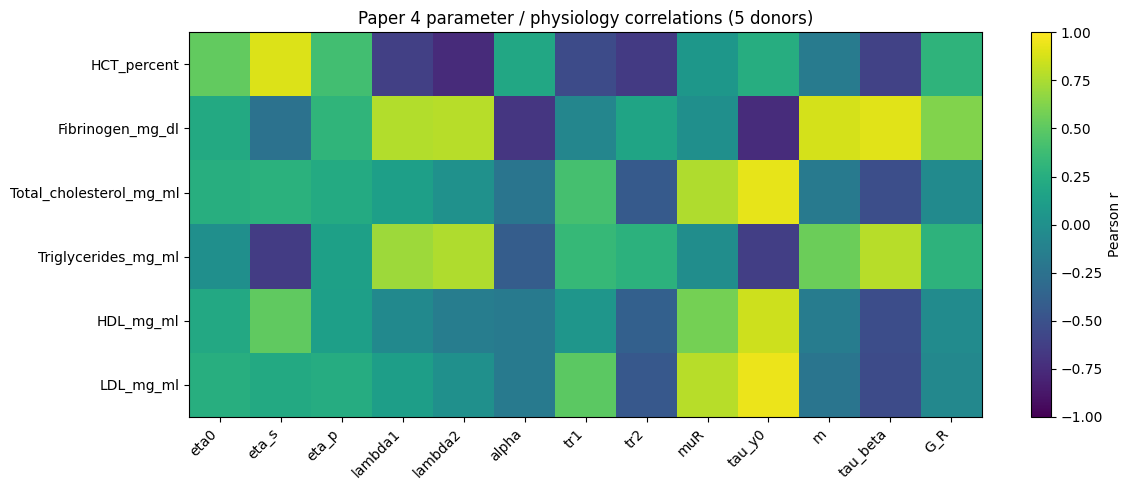

In [20]:

model_parameter_cols = [
    "eta0", "eta_s", "eta_p", "lambda1", "lambda2", "alpha",
    "tr1", "tr2", "muR", "tau_y0", "m", "tau_beta", "G_R"
]
physiology_cols = [
    "HCT_percent", "Fibrinogen_mg_dl", "Total_cholesterol_mg_ml",
    "Triglycerides_mg_ml", "HDL_mg_ml", "LDL_mg_ml"
]

master = physiology.merge(
    reported_params[["Donor"] + model_parameter_cols],
    on="Donor",
    how="inner"
)

corr = pd.DataFrame(index=physiology_cols, columns=model_parameter_cols, dtype=float)
pvals = corr.copy()

for phys in physiology_cols:
    for par in model_parameter_cols:
        r, pval = pearsonr(master[phys], master[par])
        corr.loc[phys, par] = r
        pvals.loc[phys, par] = pval

display(corr.round(3))
display(pvals.round(3))

plt.figure(figsize=(12, 5))
img = plt.imshow(corr.astype(float), aspect="auto", vmin=-1, vmax=1)
plt.colorbar(img, label="Pearson r")
plt.xticks(range(len(model_parameter_cols)), model_parameter_cols, rotation=45, ha="right")
plt.yticks(range(len(physiology_cols)), physiology_cols)
plt.title("Paper 4 parameter / physiology correlations (5 donors)")
plt.tight_layout()
plt.show()



**Interpret correlations cautiously.** Paper 4 itself emphasizes that five donors is a small sample. A large \(|r|\) can occur by chance with \(n=5\), so p-values and uncertainty should be reported alongside the coefficients.


## 10. Paper-reported benchmark against peer models

,paper_id,model,Fcost_SS,k_SS,AIC_SS,BIC_SS,Fcost_trans,k_trans,AIC_trans,BIC_trans,Fcost_LAOS,Fcost_UDLAOS,Fcost_SAOS,Fcost_total
0,4,ethixo-Giesekus,0.01210,11,14.565,53.562,0.00070,13,20.53,149.649,0.00085,0.00085,0.00251,0.00123
1,comparison source cited in Paper 4,ethixo-Convected Maxwell,0.01601,6,8.430,33.250,0.00051,10,13.45,112.770,0.00106,0.00119,0.00309,0.00146
2,comparison source cited in Paper 4,Corotational Jeffreys,0.00844,8,7.750,36.110,0.00052,11,15.51,124.770,0.00060,0.00082,0.00687,0.00220
3,comparison source cited in Paper 4,Oldroyd-4,0.01097,9,10.820,42.730,0.00076,12,19.10,138.290,0.00133,0.00243,0.00298,0.00187
4,comparison source cited in Paper 4,mHAWB,0.00619,9,8.630,40.540,0.00052,12,17.52,136.710,0.00066,0.00080,0.00169,0.00092


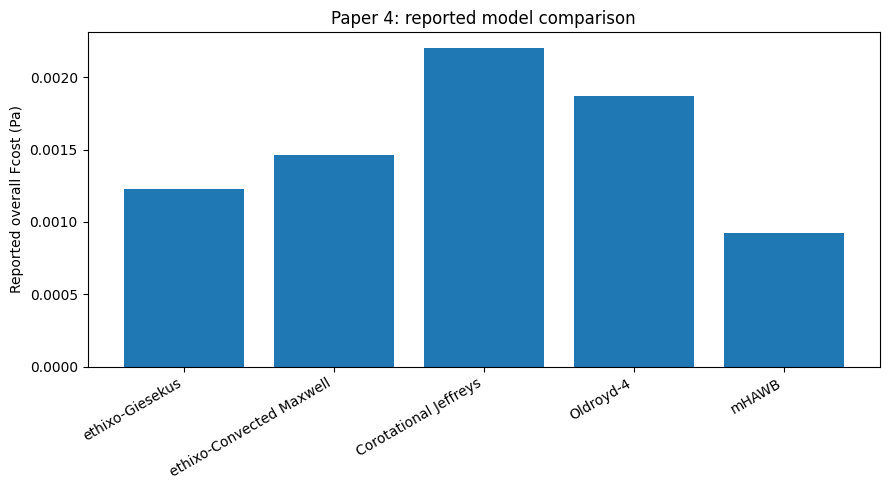

In [21]:

paper4_model_benchmark = pd.DataFrame([
    {
        "paper_id": 4,
        "model": "ethixo-Giesekus",
        "Fcost_SS": 0.0121,
        "k_SS": 11,
        "AIC_SS": 14.565,
        "BIC_SS": 53.562,
        "Fcost_trans": 0.00070,
        "k_trans": 13,
        "AIC_trans": 20.530,
        "BIC_trans": 149.649,
        "Fcost_LAOS": 0.00085,
        "Fcost_UDLAOS": 0.00085,
        "Fcost_SAOS": 0.00251,
        "Fcost_total": 0.00123,
    },
    {
        "paper_id": "comparison source cited in Paper 4",
        "model": "ethixo-Convected Maxwell",
        "Fcost_SS": 0.01601,
        "k_SS": 6,
        "AIC_SS": 8.43,
        "BIC_SS": 33.25,
        "Fcost_trans": 0.00051,
        "k_trans": 10,
        "AIC_trans": 13.45,
        "BIC_trans": 112.77,
        "Fcost_LAOS": 0.00106,
        "Fcost_UDLAOS": 0.00119,
        "Fcost_SAOS": 0.00309,
        "Fcost_total": 0.00146,
    },
    {
        "paper_id": "comparison source cited in Paper 4",
        "model": "Corotational Jeffreys",
        "Fcost_SS": 0.00844,
        "k_SS": 8,
        "AIC_SS": 7.75,
        "BIC_SS": 36.11,
        "Fcost_trans": 0.00052,
        "k_trans": 11,
        "AIC_trans": 15.51,
        "BIC_trans": 124.77,
        "Fcost_LAOS": 0.00060,
        "Fcost_UDLAOS": 0.00082,
        "Fcost_SAOS": 0.00687,
        "Fcost_total": 0.00220,
    },
    {
        "paper_id": "comparison source cited in Paper 4",
        "model": "Oldroyd-4",
        "Fcost_SS": 0.01097,
        "k_SS": 9,
        "AIC_SS": 10.82,
        "BIC_SS": 42.73,
        "Fcost_trans": 0.00076,
        "k_trans": 12,
        "AIC_trans": 19.10,
        "BIC_trans": 138.29,
        "Fcost_LAOS": 0.00133,
        "Fcost_UDLAOS": 0.00243,
        "Fcost_SAOS": 0.00298,
        "Fcost_total": 0.00187,
    },
    {
        "paper_id": "comparison source cited in Paper 4",
        "model": "mHAWB",
        "Fcost_SS": 0.00619,
        "k_SS": 9,
        "AIC_SS": 8.63,
        "BIC_SS": 40.54,
        "Fcost_trans": 0.00052,
        "k_trans": 12,
        "AIC_trans": 17.52,
        "BIC_trans": 136.71,
        "Fcost_LAOS": 0.00066,
        "Fcost_UDLAOS": 0.00080,
        "Fcost_SAOS": 0.00169,
        "Fcost_total": 0.00092,
    },
])

display(paper4_model_benchmark)

plt.figure(figsize=(9, 5))
plt.bar(paper4_model_benchmark["model"], paper4_model_benchmark["Fcost_total"])
plt.ylabel("Reported overall Fcost (Pa)")
plt.title("Paper 4: reported model comparison")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()



## 11. Cross-paper model comparison schema

When Papers 1, 2, 3, and 5 are implemented, each notebook should export **one row per donor × experiment × model** using the same columns below.

This avoids a major problem with comparing papers: each article may use a different native cost function or normalization. Therefore keep:

1. the **paper-native metric**, and
2. a **common metric calculated from the same observed/predicted points**.

Recommended common metrics:

- MAE
- RMSE
- NRMSE
- \(R^2\)
- conventional RSS
- parameter count
- runtime
- common AIC/BIC where defensible

Paper-specific metrics such as \(F_{cost}\) and \(I_3/I_1\) should remain additional columns.


In [22]:

STANDARD_RESULT_COLUMNS = [
    "paper_id",
    "paper_title_short",
    "model",
    "donor",
    "dataset",
    "experiment",
    "fit_or_prediction",
    "n_points",
    "n_fitted_parameters",
    "paper_metric_name",
    "paper_metric_value",
    "MAE",
    "RMSE",
    "NRMSE_range",
    "R2",
    "RSS_conventional",
    "AIC_common",
    "BIC_common",
    "I3_I1_data",
    "I3_I1_model",
    "runtime_s",
    "notes",
]


def make_result_row(
    model,
    donor,
    dataset,
    experiment,
    y,
    prediction,
    n_fitted_parameters,
    paper_metric_name=None,
    paper_metric_value=np.nan,
    fit_or_prediction="prediction",
    runtime_s=np.nan,
    notes="",
):
    common = common_metrics(y, prediction, k=n_fitted_parameters)
    row = {
        "paper_id": 4,
        "paper_title_short": "Integration of thixotropy into Giesekus",
        "model": model,
        "donor": donor,
        "dataset": dataset,
        "experiment": experiment,
        "fit_or_prediction": fit_or_prediction,
        "n_points": common.get("n", np.nan),
        "n_fitted_parameters": n_fitted_parameters,
        "paper_metric_name": paper_metric_name,
        "paper_metric_value": paper_metric_value,
        "MAE": common.get("MAE", np.nan),
        "RMSE": common.get("RMSE", np.nan),
        "NRMSE_range": common.get("NRMSE_range", np.nan),
        "R2": common.get("R2", np.nan),
        "RSS_conventional": common.get("RSS_conventional", np.nan),
        "AIC_common": common.get("AIC_common", np.nan),
        "BIC_common": common.get("BIC_common", np.nan),
        "I3_I1_data": np.nan,
        "I3_I1_model": np.nan,
        "runtime_s": runtime_s,
        "notes": notes,
    }
    return row


comparison_results = pd.DataFrame(columns=STANDARD_RESULT_COLUMNS)
comparison_results


,paper_id,paper_title_short,model,donor,dataset,experiment,fit_or_prediction,n_points,n_fitted_parameters,paper_metric_name,paper_metric_value,MAE,RMSE,NRMSE_range,R2,RSS_conventional,AIC_common,BIC_common,I3_I1_data,I3_I1_model,runtime_s,notes



## 12. Steady-state fitting scaffold

The paper uses a **parallel tempering** global optimization algorithm. Python does not have a single standard-library equivalent, so this notebook separates:

- the **objective function**, which should match the paper, from
- the **optimizer**, which can be swapped.

For a first Python replication, `scipy.optimize.differential_evolution` is a useful global optimizer. It is **not the same algorithm as parallel tempering**, so its results should be labeled a *Python replication of the fitting objective*, not an exact replication of the authors' optimizer.

Once the model equations are fully validated, a parallel-tempering sampler can be added without changing the rest of the framework.


In [23]:

def fit_steady_state_example(
    shear_rate,
    stress,
    initial=P1,
    use_dimensional_variant=True,
):
    shear_rate = np.asarray(shear_rate, dtype=float)
    stress = np.asarray(stress, dtype=float)

    # Starter fit: focus on parameters most directly controlling the steady-state curve.
    # Bounds should be refined from paper values / physiology before final research use.
    names = ["eta0", "lambda1", "lambda2", "alpha", "tr1", "tr2", "muR", "tau_y0", "m"]
    x0 = np.array([getattr(initial, n) for n in names], dtype=float)

    lower = np.array([
        1e-5, 1e-4, 1e-5, 1e-6, 1e-4, 1e-5, 1e-5, 0.0, 0.2
    ])
    upper = np.array([
        0.05, 5.0, 5.0, 0.99, 10.0, 10.0, 1.0, 0.1, 4.0
    ])

    def unpack(x):
        p = EthixoGiesekusParams(**asdict(initial))
        for name, value in zip(names, x):
            setattr(p, name, float(value))
        # Preserve the paper's eta0 = eta_s + eta_p relationship approximately
        # by scaling eta_s/eta_p proportions from the initial donor.
        frac_s = initial.eta_s / max(initial.eta0, 1e-12)
        p.eta_s = p.eta0 * frac_s
        p.eta_p = p.eta0 - p.eta_s
        return p

    predictor = (
        steady_total_stress_dimensional
        if use_dimensional_variant
        else steady_total_stress_as_printed
    )

    def residuals(x):
        p = unpack(x)
        pred = predictor(shear_rate, p)
        # Match Paper Eq. (21) normalization point-by-point.
        denom = np.where(np.abs(stress) > 1e-12, stress, 1e-12)
        return (stress - pred) / denom

    result = least_squares(residuals, x0, bounds=(lower, upper))
    p_best = unpack(result.x)
    pred = predictor(shear_rate, p_best)

    return {
        "params": p_best,
        "prediction": pred,
        "Fcost_SS_paper": fcost_ss_paper(stress, pred),
        "common_metrics": common_metrics(stress, pred, k=len(names)),
        "optimizer_result": result,
    }



## 13. Validation gates before claiming an exact Paper 4 reproduction

Use this checklist during the research:

- [ ] Download all five raw Mendeley donor datasets.
- [ ] Inventory workbook sheets and dimensions.
- [ ] Record exact column mappings for SS, steps, SAOS, LAOS, and UD-LAOS.
- [ ] Reproduce Donor 1 steady-state \(F_{cost}=0.0037\) to within a chosen tolerance.
- [ ] Reproduce Donor 1 transient \(F_{cost}=0.00056\) to within a chosen tolerance.
- [ ] Determine whether Eq. (14) is intended literally or requires a shear-rate factor.
- [ ] Validate the transient Giesekus tensor equations in Table I against the authors' MATLAB/source code or a trusted derivation.
- [ ] Verify the paper's printed “RSS” definition before using it in AIC/BIC.
- [ ] Reproduce \(G'_1, G''_1, G'_3, G''_3\) and \(I_3/I_1\) from oscillatory data.
- [ ] Reproduce LAOS and UD-LAOS Lissajous–Bowditch plots.
- [ ] Export standardized result rows for cross-paper comparison.

Only after these pass should the implementation be treated as an **exact replication** rather than a research reconstruction.


## 14. Export benchmark tables and future comparison results

In [ ]:

physiology.to_csv(RESULTS_ROOT / "paper4_physiology_tableII.csv", index=False)
reported_params.to_csv(RESULTS_ROOT / "paper4_reported_parameters_tableIV.csv", index=False)
paper4_model_benchmark.to_csv(RESULTS_ROOT / "paper4_reported_model_benchmark.csv", index=False)

if len(comparison_results):
    comparison_results.to_csv(
        RESULTS_ROOT / "paper4_standardized_model_results.csv",
        index=False
    )

print("Saved benchmark tables to:", RESULTS_ROOT.resolve())


Saved benchmark tables to: C:\Users\vannd\Documents\UniMelb\0_2026S1_Captstone\Capstone_2026S2\Gieskus_Model\results\paper4


: 


# Next development step

After the raw Paper 4 Mendeley workbook(s) are available locally, the next version should:

1. map the actual ARES-G2 sheets,
2. run the EDA automatically,
3. fit the steady-state model,
4. implement/validate the full transient Giesekus tensor backbone,
5. fit step-up/down parameters,
6. predict SAOS, LAOS, and UD-LAOS,
7. compare reproduced metrics with Tables III–VI,
8. export results into the shared cross-paper comparison table.

The same notebook architecture can then be reused for the other papers while swapping only the constitutive model and paper-specific fitting objective.
